# 🧠 ADReSSo Audio-First Cognitive Screening — **Final Pipeline**
### Raw audio → AD / non-AD, with explainable concept scorecard + adaptive early-exit. One run.

This is the proposed framework, nothing extra:

```
ADReSSo .wav ─► PAR-only speech (segmentation.csv) ─► split into utterances
   per utterance:  wav2vec 2.0 token  +  Whisper→BERT token      (two ALIGNED sequences)
      └─ Gated cross-attention (text⇄audio) ─► Discourse encoder (BiGRU+attn)
           └─ Concept bottleneck (24 clinical concepts) ─► Linear head
                └─ AD / non-AD  +  Confidence  +  Concept scorecard  +  Early-exit
```

**Data:** ADReSSo-2021 diagnosis **train** set. Labels from `audio/ad/` vs `audio/cn/`; diarization from `segmentation/ad|cn/*.csv`. Because the official test set is unlabeled, we split the train set into **train/val/test** (speaker-independent — one session per speaker) and report held-out **test** AUC / F1 / accuracy over several seeds.

**Fast & lean:** `large-v3-turbo` + batched ASR + mixed-precision encoders + per-file caching (resumable). The scorecard is the explainable output (instant); no slow post-hoc explainers.

> **Runtime → GPU.** Put `ADReSSo21-diagnosis-train.tgz` in Drive, set `CFG.TGZ_PATH`, then **Run all** (~20–40 min on a T4, most of it cached ASR/encoder passes).

## 0 · Install & imports

In [ ]:
import sys, subprocess
def pipq(*p): subprocess.run([sys.executable,"-m","pip","install","-q",*p], check=False)
pipq("faster-whisper","transformers","librosa","soundfile","praat-parselmouth",
     "spacy","scikit-learn","tqdm")
subprocess.run([sys.executable,"-m","spacy","download","en_core_web_sm","-q"], check=False)
import os, glob, json, csv, random, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
import torch, torch.nn as nn, torch.nn.functional as F
DEVICE="cuda" if torch.cuda.is_available() else "cpu"; AMP=(DEVICE=="cuda")
print("torch",torch.__version__,"| device:",DEVICE)
if DEVICE=="cpu": print("⚠️  No GPU — enable it (Runtime → Change runtime type).")

torch 2.11.0+cu128 | device: cuda


## 1 · Configuration

In [ ]:
class CFG:
    TGZ_PATH   = None            # e.g. "/content/drive/MyDrive/ADReSSo21-diagnosis-train.tgz"; None = auto-search
    LIMIT      = None            # None = all; set 5 for a quick smoke-test
    MIN_SEG_S  = 0.30
    WHISPER_MODEL="large-v3-turbo"   # fast+accurate; "large-v3"=best, "distil-large-v3"=EN speed
    ASR_BATCH  = 16
    W2V_MODEL  = "facebook/wav2vec2-base"
    BERT_MODEL = "bert-base-uncased"
    MAX_UTTS   = 40
    D_MODEL=128; HEADS=4; DROPOUT=0.3; LAMBDA_CONCEPT=5.0  # reverted to known-good (D64/λ8 regressed AUC); fidelity now comes from prosodic features
    EPOCHS=80; PATIENCE=15; LR=1e-3; WEIGHT_DECAY=1e-4; BATCH=16
    TEST_FRAC=0.20; VAL_FRAC=0.16          # ~64/16/20 train/val/test
    SEEDS=list(range(10))
    THRESHOLD_MODE="youden"   # operating point tuned on VALIDATION: "youden" (balanced) or "sensitivity"
    SENS_FLOOR=0.85           # min sensitivity when THRESHOLD_MODE="sensitivity" (screening mode)                       # each = fresh split+train; report mean±std
    RUN_COMPARISONS=True                    # marker baselines + black-box (proves interpretability cost); False = pipeline only
    CUTOFFS_S=[10,20,30,45,60,90,999]; KNEE_TOL=0.02
    WORK="/content/work" if os.path.isdir("/content") else "/tmp/work"
CFG.FEAT=os.path.join(CFG.WORK,"feat_v4"); CFG.TXTC=os.path.join(CFG.WORK,"txt_v4"); CFG.AUDC=os.path.join(CFG.WORK,"aud_v4")  # v4: prosodic features added -> re-extract once
for d in [CFG.WORK,CFG.FEAT,CFG.TXTC,CFG.AUDC]: os.makedirs(d,exist_ok=True)
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
set_seed(0)
# ---- fail fast if there is no GPU on a full run (extraction is impractical on CPU) ----
if DEVICE=="cpu" and CFG.LIMIT is None:
    raise RuntimeError(
        "\n>>> NO GPU DETECTED. The full 166-file run (Whisper large-v3-turbo + wav2vec2 + BERT) "
        "takes many HOURS on CPU.\n"
        ">>> FIX: Runtime -> Change runtime type -> Hardware accelerator: GPU (T4), then Run all.\n"
        ">>> To smoke-test on CPU first, set CFG.LIMIT = 3 in this config cell and re-run."
    )

print("config ready · ASR =",CFG.WHISPER_MODEL, "| device:",DEVICE)

config ready · ASR = large-v3-turbo | device: cuda


## 2 · Locate & extract ADReSSo → catalog (labels + PAR segmentation)
Handles the real layout: `audio/ad|cn/*.wav` and `segmentation/ad|cn/*.csv`.

In [ ]:
try:
    from google.colab import drive
    if not os.path.isdir("/content/drive"): drive.mount("/content/drive")
except Exception: pass
import tarfile
TGZ=CFG.TGZ_PATH
if TGZ is None:
    c=(glob.glob("/content/drive/**/ADReSSo21-diagnosis-train.tgz",recursive=True)
       +glob.glob("/content/**/ADReSSo21-diagnosis-train.tgz",recursive=True)
       +glob.glob(os.path.join(CFG.WORK,"*.tgz")))
    TGZ=c[0] if c else None
assert TGZ, "Set CFG.TGZ_PATH to ADReSSo21-diagnosis-train.tgz (mount Drive first)."
print("using tgz:",TGZ)
if not glob.glob(os.path.join(CFG.WORK,"**","*.wav"),recursive=True):
    with tarfile.open(TGZ) as t: t.extractall(CFG.WORK)

def stem(p): return os.path.splitext(os.path.basename(p))[0]
wavs=glob.glob(os.path.join(CFG.WORK,"**","*.wav"),recursive=True)
def label_of(p):
    pl=p.lower().replace("\\","/")
    if "/ad/" in pl: return 1
    if "/cn/" in pl: return 0
    return None
# segmentation csvs live under a 'segmentation' folder at ANY depth (ad/ or cn/ subfolders)
seg_files=[f for f in glob.glob(os.path.join(CFG.WORK,"**","*.csv"),recursive=True)
           if (os.sep+"segmentation"+os.sep) in f.replace("/",os.sep)]
seg_by_id={stem(f):f for f in seg_files}
def par_intervals(path):
    out=[]
    with open(path,newline="") as fh:
        r=csv.reader(fh); next(r,None)
        for row in r:
            if len(row)<4: continue
            spk=row[1].strip().strip('"').upper()
            try: b=float(row[2].strip().strip('"')); e=float(row[3].strip().strip('"'))
            except: continue
            if spk=="PAR" and e>b: out.append((b/1000.0,e/1000.0))
    return out
CATALOG={}
for w in wavs:
    y=label_of(w)
    if y is None: continue
    fid=stem(w); seg=seg_by_id.get(fid)
    CATALOG[fid]={"wav":w,"y":y,"pid":fid,"utts":par_intervals(seg) if seg else None}
ITEMS=sorted(CATALOG.items())
if CFG.LIMIT: ITEMS=ITEMS[:CFG.LIMIT]
n_ad=sum(v["y"]==1 for _,v in ITEMS); n_cn=sum(v["y"]==0 for _,v in ITEMS)
n_seg=sum(v["utts"] is not None for _,v in ITEMS)
print(f"recordings: {len(ITEMS)} (AD={n_ad}, CN={n_cn}) · with segmentation: {n_seg}/{len(ITEMS)}")
assert len(ITEMS)>0, "No labeled wavs found — check the tgz extracted to audio/ad and audio/cn."
if len({v["y"] for _,v in ITEMS})<2:
    raise RuntimeError(
        f">>> Only ONE class loaded (AD={n_ad}, CN={n_cn}). This is a LIMIT/smoke-test artifact "
        "(the first few files are all one class).\n"
        ">>> FIX: set CFG.LIMIT=None in the config cell, then Runtime -> Restart session -> Run all.")
if n_seg<len(ITEMS): print("note: files without segmentation use the whole recording as PAR speech.")

Mounted at /content/drive
using tgz: /content/drive/MyDrive/ADReSSo21-diagnosis-train.tgz
recordings: 166 (AD=87, CN=79) · with segmentation: 166/166


## 3 · Load encoders (Whisper batched, wav2vec 2.0, BERT, spaCy)

In [ ]:
from transformers import Wav2Vec2Model, AutoFeatureExtractor, AutoTokenizer, AutoModel
import librosa, parselmouth
from parselmouth.praat import call
import spacy
NLP=spacy.load("en_core_web_sm", disable=["ner","lemmatizer"])
CT="float16" if DEVICE=="cuda" else "int8"
try:
    from faster_whisper import WhisperModel, BatchedInferencePipeline
    _m=WhisperModel(CFG.WHISPER_MODEL,device=DEVICE,compute_type=CT); ASR=BatchedInferencePipeline(model=_m); BATCHED=True
    print("Whisper (batched):",CFG.WHISPER_MODEL)
except Exception as e:
    from faster_whisper import WhisperModel
    ASR=WhisperModel(CFG.WHISPER_MODEL,device=DEVICE,compute_type=CT); BATCHED=False
    print("Whisper (unbatched):",CFG.WHISPER_MODEL,"|",repr(e)[:70])
W2V_FE=AutoFeatureExtractor.from_pretrained(CFG.W2V_MODEL); W2V=Wav2Vec2Model.from_pretrained(CFG.W2V_MODEL).to(DEVICE).eval()
BTOK=AutoTokenizer.from_pretrained(CFG.BERT_MODEL); BERT=AutoModel.from_pretrained(CFG.BERT_MODEL).to(DEVICE).eval()
TEXT_DIM=BERT.config.hidden_size; W2V_DIM=W2V.config.hidden_size
print(f"encoders ready · BERT {TEXT_DIM} · wav2vec2 {W2V_DIM}")

Whisper (batched): large-v3-turbo


preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.84k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  380MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

... (8 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


encoders ready · BERT 768 · wav2vec2 768


## 4 · Feature functions (audio → aligned tokens + self-derived concepts)

In [ ]:
FILLERS={"um","uh","er","erm","hmm","mm","uhh","umm"}
def acoustic_markers(y,sr):
    f={}
    try:
        snd=parselmouth.Sound(y.astype(np.float64),sampling_frequency=sr)
        pitch=snd.to_pitch(); f0=pitch.selected_array['frequency']; f0=f0[f0>0]
        f["f0_mean"]=float(np.mean(f0)) if len(f0) else np.nan
        f["f0_std"]=float(np.std(f0)) if len(f0) else np.nan
        f["f0_range"]=float(np.ptp(f0)) if len(f0) else np.nan
        pp=call(snd,"To PointProcess (periodic, cc)",75,500)
        f["jitter_local"]=call(pp,"Get jitter (local)",0,0,1e-4,0.02,1.3)
        f["shimmer_local"]=call([snd,pp],"Get shimmer (local)",0,0,1e-4,0.02,1.3,1.6)
        h=snd.to_harmonicity_cc(); v=h.values[h.values!=-200]; f["hnr"]=float(np.mean(v)) if v.size else np.nan
    except Exception:
        for k in ["f0_mean","f0_std","f0_range","jitter_local","shimmer_local","hnr"]: f[k]=np.nan
    f["spec_centroid"]=float(np.mean(librosa.feature.spectral_centroid(y=y,sr=sr)))
    f["spec_bandwidth"]=float(np.mean(librosa.feature.spectral_bandwidth(y=y,sr=sr)))
    f["zcr"]=float(np.mean(librosa.feature.zero_crossing_rate(y)))
    f["rms_energy"]=float(np.mean(librosa.feature.rms(y=y)))
    return f
def w2v_token(seg,sr):
    if len(seg)<int(0.1*sr): seg=np.pad(seg,(0,int(0.1*sr)-len(seg)))
    with torch.no_grad(), torch.autocast(device_type="cuda",dtype=torch.float16,enabled=AMP):
        iv=W2V_FE(seg,sampling_rate=sr,return_tensors="pt").input_values.to(DEVICE)
        h=W2V(iv).last_hidden_state.mean(1).squeeze(0)
    return h.float().cpu().numpy().astype("float32")
def prosody_token(seg,sr):
    # explicit per-utterance PROSODY (Praat) -> gives the concept layer pitch/voice info wav2vec2 pools away
    f=np.zeros(8,"float32")
    try:
        if len(seg)<int(0.12*sr): return f
        snd=parselmouth.Sound(seg.astype(np.float64),sampling_frequency=sr)
        pitch=snd.to_pitch(); f0=pitch.selected_array["frequency"]; f0=f0[f0>0]
        if len(f0): f[0]=np.mean(f0)/100.0; f[1]=np.std(f0)/50.0; f[2]=np.ptp(f0)/150.0
        pp=call(snd,"To PointProcess (periodic, cc)",75,500)
        f[3]=call(pp,"Get jitter (local)",0,0,1e-4,0.02,1.3)*100.0
        f[4]=call([snd,pp],"Get shimmer (local)",0,0,1e-4,0.02,1.3,1.6)*10.0
        h=snd.to_harmonicity_cc(); v=h.values[h.values!=-200]; f[5]=(float(np.mean(v))/20.0) if v.size else 0.0
        inten=snd.to_intensity(); iv=inten.values[inten.values>0]
        if iv.size: f[6]=float(np.mean(iv))/60.0; f[7]=float(np.std(iv))/20.0
    except Exception: pass
    return np.nan_to_num(f,nan=0.0,posinf=0.0,neginf=0.0).astype("float32")
def bert_tokens(texts):
    texts=[t if t.strip() else "." for t in texts]; out=[]
    with torch.no_grad(), torch.autocast(device_type="cuda",dtype=torch.float16,enabled=AMP):
        for j in range(0,len(texts),64):
            enc=BTOK(texts[j:j+64],padding=True,truncation=True,max_length=48,return_tensors="pt").to(DEVICE)
            o=BERT(**enc).last_hidden_state; m=enc["attention_mask"].unsqueeze(-1)
            out.append(((o*m).sum(1)/m.sum(1).clamp(min=1)).float().cpu().numpy())
    return np.vstack(out).astype("float32")
def linguistic_markers(words,n_sent,dur,gaps,filled_count=None):
    n=len(words)
    if n==0: return None
    pos=[t.pos_ for t in NLP(" ".join(words))]
    pron=sum(1 for p in pos if p=="PRON"); noun=pos.count("NOUN"); verb=pos.count("VERB")
    content=sum(1 for p in pos if p in {"NOUN","VERB","ADJ","ADV"})
    Wn=25; uniq=len(set(words))
    mattr=float(np.mean([len(set(words[i:i+Wn]))/Wn for i in range(0,max(1,n-Wn+1))])) if n>=Wn else uniq/n
    filled=filled_count if filled_count is not None else sum(1 for w in words if w.lower() in FILLERS); gaps=np.array(gaps,float)
    return {"ttr":uniq/n,"mattr":mattr,"mlu_words":n/max(1,n_sent),
            "pronoun_ratio":pron/n,"noun_ratio":noun/n,"verb_ratio":verb/n,
            "pronoun_noun_ratio":pron/max(1,noun),"noun_verb_ratio":noun/max(1,verb),
            "lexical_density":content/n,"filled_pause_rate":filled/n,
            "speech_rate_wpm":(n/(dur/60.0)) if dur>0 else np.nan,
            "mean_pause_ms":float(np.mean(gaps)*1000) if len(gaps) else np.nan,
            "long_pause_ratio":float((gaps>2.0).mean()) if len(gaps) else np.nan}
print("feature functions ready")

feature functions ready


### Stage: extract aligned tokens over all recordings (cached, resumable)

In [ ]:
def build_patient(y,sr,utts,dur_full):
    if not utts: utts=[(0.0,dur_full)]
    sil=np.zeros(int(0.1*sr),"float32"); parts=[]; spans=[]; seg_audio=[]; real=[]; t=0.0; rt=0.0
    for (s,e) in utts:
        if (e-s)<CFG.MIN_SEG_S: continue
        seg=y[int(s*sr):int(e*sr)]
        if len(seg)<int(0.05*sr): continue
        parts+=[seg,sil]; spans.append((t,t+len(seg)/sr)); seg_audio.append(seg); real.append(rt)
        t+=len(seg)/sr+0.1; rt+=len(seg)/sr
    yp=np.concatenate(parts) if parts else y
    if not seg_audio: seg_audio=[y]; spans=[(0.0,len(y)/sr)]; real=[0.0]; rt=len(y)/sr
    return yp,spans,seg_audio,real,rt
def transcribe_words(yp):
    if BATCHED: segs,_=ASR.transcribe(yp,batch_size=CFG.ASR_BATCH,word_timestamps=True)
    else: segs,_=ASR.transcribe(yp,word_timestamps=True)
    W=[]
    for s in segs:
        if s.words:
            for w in s.words: W.append((w.start,w.end,w.word.strip()))
    return W
_CONCEPT_KEYS=["ttr","mattr","mlu_words","pronoun_ratio","noun_ratio","verb_ratio","pronoun_noun_ratio",
               "noun_verb_ratio","lexical_density","filled_pause_rate","speech_rate_wpm","mean_pause_ms","long_pause_ratio"]
from tqdm.auto import tqdm
made=done=0
for fid,v in tqdm(ITEMS,desc="extract"):
    fj=os.path.join(CFG.FEAT,f"{fid}.json"); ft=os.path.join(CFG.TXTC,f"{fid}.npy"); fa=os.path.join(CFG.AUDC,f"{fid}.npy")
    if os.path.exists(fj) and os.path.exists(ft) and os.path.exists(fa): done+=1; continue
    try:
        y,sr=librosa.load(v["wav"],sr=16000,mono=True); dur_full=len(y)/sr
        yp,spans,seg_audio,real,pdur=build_patient(y,sr,v["utts"],dur_full)
        words=transcribe_words(yp)
        seg_text=[[] for _ in spans]
        for ws,we,w in words:
            c=0.5*(ws+we)
            for i,(a,b) in enumerate(spans):
                if a<=c<=b: seg_text[i].append(w); break
        utt_texts=[" ".join(t) for t in seg_text][:CFG.MAX_UTTS] or ["."]
        seg_audio=seg_audio[:CFG.MAX_UTTS]; real=real[:CFG.MAX_UTTS]
        Ltok=bert_tokens(utt_texts); Atok=np.vstack([np.concatenate([w2v_token(s,sr), prosody_token(s,sr)]) for s in seg_audio]).astype("float32")  # wav2vec2 (768) + prosody (8)
        m=min(len(Ltok),len(Atok)); Ltok,Atok=Ltok[:m],Atok[:m]
        allw=[w for t in seg_text for w in t]
        gaps=[max(0.0,words[i][0]-words[i-1][1]) for i in range(1,len(words))]
        # ACOUSTIC filled-pause detection: a VOICED gap between words = a filled pause ('uhh'), ASR-independent
        speech_rms=float(np.sqrt(np.mean(yp**2)+1e-9)); n_filled=0
        for gi in range(1,len(words)):
            gs,ge=words[gi-1][1],words[gi][0]
            if (ge-gs)<0.15: continue
            gseg=yp[int(gs*sr):int(ge*sr)]
            if len(gseg)<int(0.05*sr): continue
            if np.sqrt(np.mean(gseg**2)+1e-9) > 0.35*speech_rms: n_filled+=1
        lmk=linguistic_markers(allw,max(1,len([t for t in utt_texts if t.strip()])),pdur,gaps,filled_count=n_filled) or {k:0.0 for k in _CONCEPT_KEYS}
        amk=acoustic_markers(yp,sr)
        rec={**lmk,**amk,"y":int(v["y"]),"pid":v["pid"],"file":fid,
             "seg_meta":[[round(real[i],2)," ".join(seg_text[i])] for i in range(m)],
             "asr_words":[[round(ws,2),round(we,2),w] for ws,we,w in words]}
        json.dump(rec,open(fj,"w")); np.save(ft,Ltok); np.save(fa,Atok); made+=1
    except Exception as e:
        print("skip",fid,"→",repr(e)[:120])
print(f"features: made {made}, cached {done}, total {len(glob.glob(os.path.join(CFG.FEAT,'*.json')))}")

extract:   0%|          | 0/166 [00:00<?, ?it/s]

features: made 166, cached 0, total 166


## 5 · Collect features

In [ ]:
LING=["ttr","mattr","mlu_words","pronoun_ratio","noun_ratio","verb_ratio",
      "pronoun_noun_ratio","noun_verb_ratio","lexical_density","filled_pause_rate",
      "speech_rate_wpm","mean_pause_ms","long_pause_ratio"]
VOICE=["f0_mean","f0_std","f0_range","jitter_local","shimmer_local","hnr",
       "spec_centroid","spec_bandwidth","zcr","rms_energy"]
CONCEPTS=LING+VOICE
rows=[]; TXT={}; AUD={}; SEG={}
for fj in glob.glob(os.path.join(CFG.FEAT,"*.json")):
    r=json.load(open(fj)); fid=r["file"]
    ft=os.path.join(CFG.TXTC,f"{fid}.npy"); fa=os.path.join(CFG.AUDC,f"{fid}.npy")
    if not (os.path.exists(ft) and os.path.exists(fa)): continue
    TXT[fid]=np.load(ft).astype("float32"); AUD[fid]=np.load(fa).astype("float32"); SEG[fid]=r["seg_meta"]; rows.append(r)
df=pd.DataFrame(rows)
for c in CONCEPTS: df[c]=pd.to_numeric(df[c],errors="coerce"); df[c]=df[c].fillna(df[c].median())
df=df.reset_index(drop=True)
Y=df["y"].values.astype("float32"); GROUPS=df["pid"].astype(str).values; FILES=df["file"].astype(str).values
C_all=df[CONCEPTS].values.astype("float32")
TEXT_DIM=next(iter(TXT.values())).shape[1]; AUD_DIM=next(iter(AUD.values())).shape[1]
print(f"collected {len(df)} | concepts {len(CONCEPTS)} | text {TEXT_DIM} | audio {AUD_DIM}")
print("labels:", {int(k):int(v) for k,v in df['y'].value_counts().items()})

collected 166 | concepts 23 | text 768 | audio 776
labels: {1: 87, 0: 79}


## 6 · Model — gated cross-attention → discourse encoder → concept bottleneck

In [ ]:
class CrossAttnFusion(nn.Module):
    def __init__(self,d_text,d_aud,d=128,heads=4,dropout=0.3,maxlen=40):
        super().__init__()
        self.ln_l_in=nn.LayerNorm(d_text); self.ln_a_in=nn.LayerNorm(d_aud)
        self.pl=nn.Linear(d_text,d); self.pa=nn.Linear(d_aud,d); self.pos=nn.Embedding(maxlen,d)
        self.l2a=nn.MultiheadAttention(d,heads,dropout=dropout,batch_first=True)
        self.a2l=nn.MultiheadAttention(d,heads,dropout=dropout,batch_first=True)
        self.ln_l=nn.LayerNorm(d); self.ln_a=nn.LayerNorm(d); self.gate=nn.Linear(2*d,d); self.drop=nn.Dropout(dropout)
    def forward(self,L,A,mask):
        T=L.size(1); pos=self.pos(torch.arange(T,device=L.device))[None]
        L=self.pl(self.ln_l_in(L))+pos; A=self.pa(self.ln_a_in(A))+pos; kpm=~mask
        Lc,_=self.l2a(L,A,A,key_padding_mask=kpm); Ac,_=self.a2l(A,L,L,key_padding_mask=kpm)
        L=self.ln_l(L+Lc); A=self.ln_a(A+Ac); g=torch.sigmoid(self.gate(torch.cat([L,A],-1)))
        return self.drop(torch.relu(g*L+(1-g)*A))
class DiscourseEncoder(nn.Module):
    def __init__(self,d,hid=64,out=128,dropout=0.3):
        super().__init__(); self.gru=nn.GRU(d,hid,batch_first=True,bidirectional=True)
        self.attn=nn.Linear(2*hid,1); self.proj=nn.Sequential(nn.Linear(2*hid,out),nn.ReLU(),nn.Dropout(dropout))
    def forward(self,x,lens):
        p=nn.utils.rnn.pack_padded_sequence(x,lens.cpu().clamp(min=1),batch_first=True,enforce_sorted=False)
        o,_=self.gru(p); o,_=nn.utils.rnn.pad_packed_sequence(o,batch_first=True,total_length=x.size(1))
        m=torch.arange(o.size(1),device=x.device)[None,:]<lens[:,None].clamp(min=1)
        s=self.attn(o).squeeze(-1).masked_fill(~m,float("-inf")); w=torch.softmax(s,1).unsqueeze(-1)
        return self.proj((o*w).sum(1))
class Net(nn.Module):
    def __init__(self,text_dim,aud_dim,n_concepts,d=128,heads=4,dropout=0.3,bottleneck=True,maxlen=40):
        super().__init__(); self.bottleneck=bottleneck
        self.fusion=CrossAttnFusion(text_dim,aud_dim,d,heads,dropout,maxlen); self.disc=DiscourseEncoder(d,64,128,dropout)
        if bottleneck: self.to_concepts=nn.Linear(128,n_concepts); self.head=nn.Linear(n_concepts,1)
        else: self.head=nn.Sequential(nn.Linear(128,64),nn.ReLU(),nn.Dropout(dropout),nn.Linear(64,1))
    def forward(self,L,A,lens):
        mask=torch.arange(L.size(1),device=L.device)[None,:]<lens[:,None].clamp(min=1)
        H=self.fusion(L,A,mask); D=self.disc(H,lens)
        if self.bottleneck: c=self.to_concepts(D); return self.head(c).squeeze(-1), c
        return self.head(D).squeeze(-1), None
print("model defined · cross-attention + discourse + bottleneck")

model defined · cross-attention + discourse + bottleneck


## 7 · Train / val / test split (speaker-independent) + training

In [ ]:
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score, f1_score
MAXU=CFG.MAX_UTTS
def pad_pair(fid):
    L=TXT[fid]; A=AUD[fid]; n=min(len(L),len(A),MAXU)
    tl=np.zeros((MAXU,L.shape[1]),"float32"); tl[:n]=L[:n]
    ta=np.zeros((MAXU,A.shape[1]),"float32"); ta[:n]=A[:n]
    return tl,ta,max(1,n)
class DS(Dataset):
    def __init__(self,idx,C): self.idx=idx; self.C=C
    def __len__(self): return len(self.idx)
    def __getitem__(self,k):
        i=self.idx[k]; L,A,n=pad_pair(FILES[i])
        return torch.from_numpy(L),torch.from_numpy(A),n,torch.tensor(Y[i]),torch.from_numpy(self.C[i])
def collate(b):
    L,A,n,y,c=zip(*b); return torch.stack(L),torch.stack(A),torch.tensor(n),torch.stack(y),torch.stack(c)
def run_epoch(net,dl,opt=None,lam=1.0):
    train=opt is not None; net.train() if train else net.eval(); P=[];T=[]
    for L,A,n,y,c in dl:
        L,A,n,y,c=[x.to(DEVICE) for x in (L,A,n,y,c)]
        with torch.set_grad_enabled(train):
            logit,cp=net(L,A,n); loss=F.binary_cross_entropy_with_logits(logit,y)
            if net.bottleneck and cp is not None: loss=loss+lam*F.mse_loss(cp,c)
            if train: opt.zero_grad(); loss.backward(); opt.step()
        P.append(torch.sigmoid(logit).detach().cpu().numpy()); T.append(y.cpu().numpy())
    return np.concatenate(P),np.concatenate(T)
def split_idx(seed):
    idx=np.arange(len(df))
    tr,te=train_test_split(idx,test_size=CFG.TEST_FRAC,stratify=Y,random_state=seed)
    tr,va=train_test_split(tr,test_size=CFG.VAL_FRAC/(1-CFG.TEST_FRAC),stratify=Y[tr],random_state=seed)
    return tr,va,te
def train_once(tr,va,te,C,bottleneck=True,seed=0):
    set_seed(seed)
    net=Net(TEXT_DIM,AUD_DIM,len(CONCEPTS),CFG.D_MODEL,CFG.HEADS,CFG.DROPOUT,bottleneck,MAXU).to(DEVICE)
    opt=torch.optim.Adam(net.parameters(),lr=CFG.LR,weight_decay=CFG.WEIGHT_DECAY)
    dtr=DataLoader(DS(tr,C),batch_size=CFG.BATCH,shuffle=True,collate_fn=collate)
    dva=DataLoader(DS(va,C),batch_size=CFG.BATCH,shuffle=False,collate_fn=collate)
    dte=DataLoader(DS(te,C),batch_size=CFG.BATCH,shuffle=False,collate_fn=collate)
    best=-1;bs=None;wait=0
    for ep in range(CFG.EPOCHS):
        run_epoch(net,dtr,opt,CFG.LAMBDA_CONCEPT)
        Pv,Tv=run_epoch(net,dva); auc=roc_auc_score(Tv,Pv) if len(set(Tv))>1 else 0.5
        if auc>best: best=auc; bs={k:v.cpu().clone() for k,v in net.state_dict().items()}; wait=0
        else:
            wait+=1
            if wait>=CFG.PATIENCE: break
    net.load_state_dict(bs)
    Pv,Tv=run_epoch(net,dva); Pt,Tt=run_epoch(net,dte)   # val preds -> threshold; test preds -> metrics
    return net,Pt,Tt,Pv,Tv,te
from sklearn.metrics import confusion_matrix
def pick_threshold(Pv,Tv):
    # choose the decision threshold on VALIDATION predictions (never on test -> no leakage)
    if len(set(Tv))<2: return 0.5
    best_t,best=0.5,-1.0
    for t in np.unique(np.concatenate([[0.0],np.sort(Pv),[1.0]])):
        pred=(Pv>=t).astype(int); tn,fp,fn,tp=confusion_matrix(Tv,pred,labels=[0,1]).ravel()
        sens=tp/(tp+fn) if (tp+fn) else 0.0; spec=tn/(tn+fp) if (tn+fp) else 0.0
        score=(spec if sens>=CFG.SENS_FLOOR else sens-1.0) if CFG.THRESHOLD_MODE=="sensitivity" else (sens+spec-1.0)
        if score>best: best=score; best_t=float(t)
    return best_t
print("training utilities ready · threshold tuning on")

training utilities ready · threshold tuning on


## 8 · Train the pipeline → held-out TEST results

In [ ]:
def run_deep(bottleneck):
    preds=[]                                  # (P,T) per seed -> reused for all paper metrics
    for s in CFG.SEEDS:
        tr,va,te=split_idx(s)
        if len(set(Y[te]))<2: continue        # AUC undefined on a single-class test fold
        sc=StandardScaler().fit(C_all[tr]); C=sc.transform(C_all).astype("float32")
        _,Pt,Tt,Pv,Tv,_=train_once(tr,va,te,C,bottleneck,s)
        thr=pick_threshold(Pv,Tv)
        preds.append((Pt,Tt,thr))
        if bottleneck:
            pred=(Pt>=thr).astype(int)
            print(f"    seed {s}: AUC {roc_auc_score(Tt,Pt):.3f}  F1 {f1_score(Tt,pred):.3f}  acc {(pred==Tt).mean():.3f}  thr {thr:.2f}")
    return preds
def summ(preds):
    A=[roc_auc_score(T,P) for P,T,_ in preds]; F=[f1_score(T,(P>=th).astype(int)) for P,T,th in preds]
    return (np.mean(A),np.std(A)), np.mean(F)

print("▶ Concept-bottleneck pipeline (OURS):")
PREDS_CB=run_deep(True); cb=summ(PREDS_CB)

lines=[]; PREDS_BB=None
if CFG.RUN_COMPARISONS:
    from sklearn.pipeline import make_pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.linear_model import LogisticRegression
    from sklearn.ensemble import RandomForestClassifier
    def baseline(cols,mk):
        a=[];f=[]
        for s in CFG.SEEDS:
            tr,va,te=split_idx(s); trv=np.concatenate([tr,va])
            if len(set(Y[trv]))<2 or len(set(Y[te]))<2: continue
            X=df[cols].values; mdl=mk(); mdl.fit(X[trv],Y[trv]); p=mdl.predict_proba(X[te])[:,1]
            a.append(roc_auc_score(Y[te],p)); f.append(f1_score(Y[te],(p>=.5).astype(int)))
        return (np.mean(a) if a else float("nan")),(np.mean(f) if f else float("nan"))
    b1=baseline(LING, lambda: make_pipeline(SimpleImputer(),StandardScaler(),LogisticRegression(max_iter=1000)))
    b2=baseline(CONCEPTS, lambda: make_pipeline(SimpleImputer(),RandomForestClassifier(n_estimators=300,random_state=0)))
    print("▶ Black-box (same encoders+fusion, MLP head):"); PREDS_BB=run_deep(False); bb=summ(PREDS_BB)
    lines=[("Linguistic markers + LogReg",b1[0],b1[1]),
           ("All markers + RandomForest",b2[0],b2[1]),
           ("Black-box (cross-attn)",bb[0][0],bb[1])]

print("\n"+"="*58)
print(f"{'Model':<38}{'test AUC':>10}{'F1':>8}")
print("-"*58)
for name,auc,f1 in lines: print(f"{name:<38}{auc:>10.3f}{f1:>8.3f}")
print(f"{'Concept-bottleneck (OURS)':<38}{cb[0][0]:>7.3f}±{cb[0][1]:.2f}{cb[1]:>8.3f}")
print("-"*58)
if CFG.RUN_COMPARISONS: print(f"Interpretability cost (blackbox − bottleneck): {bb[0][0]-cb[0][0]:+.3f} AUC")
print("="*58)
print("(AUC is threshold-free; F1 for deep models uses the validation-tuned threshold, baselines use 0.5)")

▶ Concept-bottleneck pipeline (OURS):
    seed 0: AUC 0.819  F1 0.750  acc 0.706  thr 0.36
    seed 1: AUC 0.767  F1 0.727  acc 0.735  thr 0.55
    seed 2: AUC 0.847  F1 0.743  acc 0.735  thr 0.50
    seed 3: AUC 0.920  F1 0.914  acc 0.912  thr 0.45
    seed 4: AUC 0.882  F1 0.714  acc 0.765  thr 0.52
    seed 5: AUC 0.753  F1 0.727  acc 0.735  thr 0.51
    seed 6: AUC 0.736  F1 0.667  acc 0.647  thr 0.47
    seed 7: AUC 0.826  F1 0.615  acc 0.706  thr 0.59
    seed 8: AUC 0.892  F1 0.829  acc 0.794  thr 0.44
    seed 9: AUC 0.517  F1 0.414  acc 0.500  thr 0.55
▶ Black-box (same encoders+fusion, MLP head):

Model                                   test AUC      F1
----------------------------------------------------------
Linguistic markers + LogReg                0.852   0.779
All markers + RandomForest                 0.844   0.800
Black-box (cross-attn)                     0.812   0.700
Concept-bottleneck (OURS)               0.796±0.11   0.710
---------------------------------------

## 8b · Research-paper metrics (held-out test, mean ± std over seeds)
Full metric suite for the concept-bottleneck model — ROC-AUC, PR-AUC (AUPRC), accuracy, balanced accuracy, sensitivity, specificity, precision, F1, MCC — plus mean ROC and Precision–Recall curves with ±1 std bands and a pooled confusion matrix.

CONCEPT-BOTTLENECK — test metrics (mean ± std, 10 seeds)
operating threshold = validation-tuned (youden), mean 0.49
  AUC            0.796 ± 0.110
  AUPRC          0.826 ± 0.096
  Accuracy       0.724 ± 0.099
  Balanced acc   0.727 ± 0.098
  Sensitivity    0.672 ± 0.182
  Specificity    0.781 ± 0.151
  Precision      0.794 ± 0.142
  F1             0.710 ± 0.126
  MCC            0.473 ± 0.201


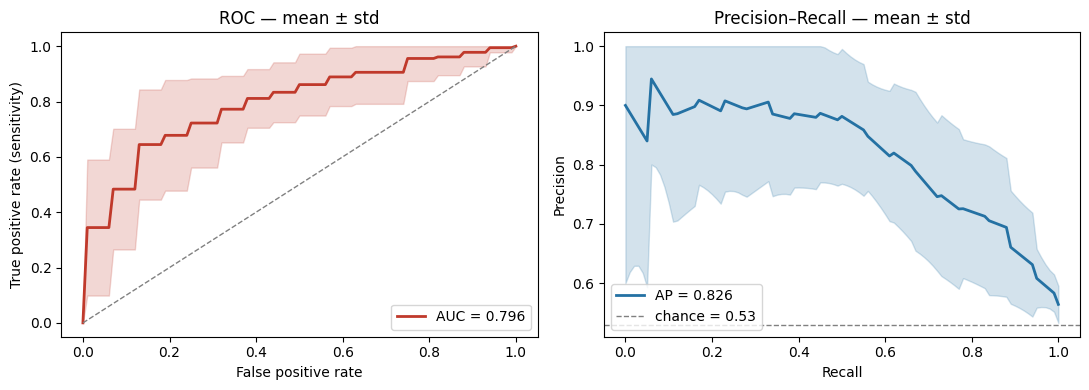

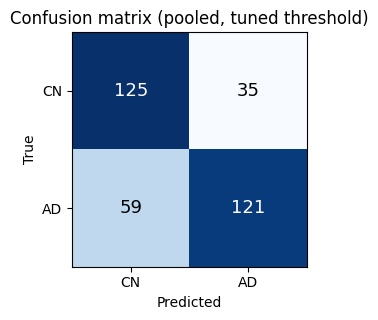

Pooled: sensitivity (AD recall) = 0.672 | specificity (CN recall) = 0.781


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
    accuracy_score, balanced_accuracy_score, matthews_corrcoef, confusion_matrix,
    roc_curve, precision_recall_curve)

def metrics_table(preds):
    keys=["AUC","AUPRC","Accuracy","Balanced acc","Sensitivity","Specificity","Precision","F1","MCC"]
    M={k:[] for k in keys}
    for P,T,thr in preds:
        pred=(P>=thr).astype(int)
        tn,fp,fn,tp=confusion_matrix(T,pred,labels=[0,1]).ravel()
        M["AUC"].append(roc_auc_score(T,P)); M["AUPRC"].append(average_precision_score(T,P))
        M["Accuracy"].append(accuracy_score(T,pred)); M["Balanced acc"].append(balanced_accuracy_score(T,pred))
        M["Sensitivity"].append(tp/(tp+fn) if (tp+fn) else np.nan)
        M["Specificity"].append(tn/(tn+fp) if (tn+fp) else np.nan)
        M["Precision"].append(precision_score(T,pred,zero_division=0))
        M["F1"].append(f1_score(T,pred,zero_division=0)); M["MCC"].append(matthews_corrcoef(T,pred))
    return keys,M

keys,M=metrics_table(PREDS_CB)
avg_thr=np.mean([thr for _,_,thr in PREDS_CB])
print("="*52); print(f"CONCEPT-BOTTLENECK — test metrics (mean ± std, {len(PREDS_CB)} seeds)")
print(f"operating threshold = validation-tuned ({CFG.THRESHOLD_MODE}), mean {avg_thr:.2f}"); print("="*52)
for k in keys: print(f"  {k:<14} {np.nanmean(M[k]):.3f} ± {np.nanstd(M[k]):.3f}")

def mean_curve(preds, kind):
    grid=np.linspace(0,1,101); ys=[]
    for P,T,_ in preds:
        if kind=="roc":
            x,y,_=roc_curve(T,P); yi=np.interp(grid,x,y); yi[0]=0.0
        else:
            pr,rc,_=precision_recall_curve(T,P); o=np.argsort(rc); yi=np.interp(grid,rc[o],pr[o])
        ys.append(yi)
    ys=np.array(ys); return grid, ys.mean(0), ys.std(0)

fig,ax=plt.subplots(1,2,figsize=(11,4))
g,m,s=mean_curve(PREDS_CB,"roc"); auc=np.mean([roc_auc_score(T,P) for P,T,_ in PREDS_CB])
ax[0].plot(g,m,color="#c0392b",lw=2,label=f"AUC = {auc:.3f}"); ax[0].fill_between(g,np.clip(m-s,0,1),np.clip(m+s,0,1),color="#c0392b",alpha=.2)
ax[0].plot([0,1],[0,1],"--",c="gray",lw=1); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate (sensitivity)")
ax[0].set_title("ROC — mean ± std"); ax[0].legend(loc="lower right")
g,m,s=mean_curve(PREDS_CB,"pr"); ap=np.mean([average_precision_score(T,P) for P,T,_ in PREDS_CB]); base=np.mean([np.mean(T) for _,T,_ in PREDS_CB])
ax[1].plot(g,m,color="#2471a3",lw=2,label=f"AP = {ap:.3f}"); ax[1].fill_between(g,np.clip(m-s,0,1),np.clip(m+s,0,1),color="#2471a3",alpha=.2)
ax[1].axhline(base,ls="--",c="gray",lw=1,label=f"chance = {base:.2f}"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision–Recall — mean ± std"); ax[1].legend(loc="lower left"); plt.tight_layout(); plt.show()

CM=np.zeros((2,2),int)
for P,T,thr in PREDS_CB: CM+=confusion_matrix(T,(P>=thr).astype(int),labels=[0,1])
plt.figure(figsize=(3.7,3.3)); plt.imshow(CM,cmap="Blues")
for r in range(2):
    for cx in range(2):
        plt.text(cx,r,CM[r,cx],ha="center",va="center",fontsize=13,color="white" if CM[r,cx]>CM.max()/2 else "black")
plt.xticks([0,1],["CN","AD"]); plt.yticks([0,1],["CN","AD"]); plt.xlabel("Predicted"); plt.ylabel("True")
plt.title("Confusion matrix (pooled, tuned threshold)"); plt.tight_layout(); plt.show()
sens=CM[1,1]/max(1,CM[1,1]+CM[1,0]); spec=CM[0,0]/max(1,CM[0,0]+CM[0,1])
print(f"Pooled: sensitivity (AD recall) = {sens:.3f} | specificity (CN recall) = {spec:.3f}")

## 9 · Explainability audit — all 23 concepts
Global importance (all 23) + **concept fidelity** (do the bottleneck neurons recover the real markers?) + **group-difference** validation (do markers move the clinically-expected way?) + per-patient natural-language explanations and full scorecards.

GLOBAL CONCEPT IMPORTANCE — all 23 (signed toward AD)
  pronoun_ratio       +0.362  ↑AD
  long_pause_ratio    +0.354  ↑AD
  ttr                 +0.297  ↑AD
  f0_mean             +0.289  ↑AD
  mattr               -0.263  ↓AD
  speech_rate_wpm     -0.239  ↓AD
  noun_verb_ratio     -0.231  ↓AD
  f0_std              -0.228  ↓AD
  spec_bandwidth      -0.150  ↓AD
  mlu_words           -0.119  ↓AD
  rms_energy          +0.110  ↑AD
  filled_pause_rate   -0.110  ↓AD
  jitter_local        +0.104  ↑AD
  lexical_density     +0.088  ↑AD
  noun_ratio          +0.088  ↑AD
  verb_ratio          +0.084  ↑AD
  zcr                 -0.065  ↓AD
  mean_pause_ms       +0.060  ↑AD
  pronoun_noun_ratio  +0.031  ↑AD
  hnr                 +0.019  ↑AD
  spec_centroid       +0.017  ↑AD
  shimmer_local       +0.016  ↑AD
  f0_range            -0.009  ↓AD


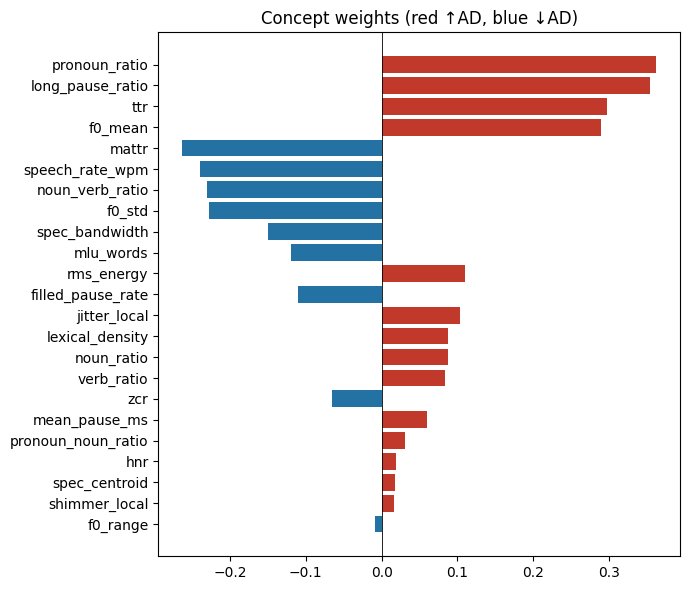


CONCEPT FIDELITY  (model-predicted vs true marker, test set)
  ttr                  r=+0.02
  mattr                r=-0.20
  mlu_words            r=+0.99
  pronoun_ratio        r=+0.54
  noun_ratio           r=+0.48
  verb_ratio           r=+0.12
  pronoun_noun_ratio   r=+0.54
  noun_verb_ratio      r=+0.38
  lexical_density      r=+0.47
  filled_pause_rate    r=+0.53
  speech_rate_wpm      r=+0.79
  mean_pause_ms        r=+0.65
  long_pause_ratio     r=+0.61
  f0_mean              r=+0.43
  f0_std               r=+0.47
  f0_range             r=+0.00
  jitter_local         r=+0.32
  shimmer_local        r=+0.71
  hnr                  r=+0.56
  spec_centroid        r=+0.62
  spec_bandwidth       r=+0.81
  zcr                  r=+0.43
  rms_energy           r=+0.73

  mean fidelity r = 0.48   (→1 = bottleneck faithfully reconstructs the real markers)

AD vs CN group difference  (Cohen's d, raw markers)
  speech_rate_wpm      d=-0.83  (higher in CN)
  mean_pause_ms        d=+0.75  (highe

In [ ]:
import matplotlib.pyplot as plt
from scipy.stats import pearsonr

# reference model (seed 0) for the interpretability audit
tr,va,te = split_idx(0)
sc = StandardScaler().fit(C_all[tr]); C = sc.transform(C_all).astype("float32")
net,Pte,Tte,_,_,idx = train_once(tr,va,te,C,True,0)
W = net.head.weight.detach().cpu().numpy().ravel(); b = net.head.bias.item()

@torch.no_grad()
def concepts_for(i):
    L,A,n = pad_pair(FILES[i])
    _,c = net(torch.from_numpy(L)[None].to(DEVICE),torch.from_numpy(A)[None].to(DEVICE),torch.tensor([n]).to(DEVICE))
    return c.cpu().numpy().ravel()

# ---------- (1) GLOBAL IMPORTANCE — all 23 concepts ----------
order = np.argsort(-np.abs(W))
print("="*58); print("GLOBAL CONCEPT IMPORTANCE — all 23 (signed toward AD)"); print("="*58)
for j in order: print(f"  {CONCEPTS[j]:<20}{W[j]:+.3f}  {'↑AD' if W[j]>0 else '↓AD'}")
plt.figure(figsize=(7,6))
cols=["#c0392b" if W[j]>0 else "#2471a3" for j in order]
plt.barh([CONCEPTS[j] for j in order][::-1],[W[j] for j in order][::-1],color=cols[::-1])
plt.axvline(0,c="k",lw=.6); plt.title("Concept weights (red ↑AD, blue ↓AD)"); plt.tight_layout(); plt.show()

# ---------- (2) CONCEPT FIDELITY — do the bottleneck neurons recover the REAL markers? ----------
Cpred=np.vstack([concepts_for(i) for i in te]); Ctrue=C[te]
print("\n"+"="*58); print("CONCEPT FIDELITY  (model-predicted vs true marker, test set)"); print("="*58)
fid=[]
for j in range(len(CONCEPTS)):
    r=pearsonr(Cpred[:,j],Ctrue[:,j])[0] if np.std(Cpred[:,j])>1e-6 else np.nan
    fid.append(r); print(f"  {CONCEPTS[j]:<20} r={r:+.2f}")
print(f"\n  mean fidelity r = {np.nanmean(fid):.2f}   (→1 = bottleneck faithfully reconstructs the real markers)")

# ---------- (3) GROUP DIFFERENCE — do markers move the clinically-expected way? ----------
print("\n"+"="*58); print("AD vs CN group difference  (Cohen's d, raw markers)"); print("="*58)
gd=[]
for c in CONCEPTS:
    ad=df.loc[df.y==1,c].values; cn=df.loc[df.y==0,c].values
    sp=np.sqrt((ad.var(ddof=1)+cn.var(ddof=1))/2)+1e-9; gd.append((c,(ad.mean()-cn.mean())/sp))
for c,d in sorted(gd,key=lambda x:-abs(x[1])):
    print(f"  {c:<20} d={d:+.2f}  ({'higher in AD' if d>0 else 'higher in CN'})")

Per-patient natural-language explanation + full 23-concept scorecard:

── adrso152  (true: CN) ──
  Predicted control-consistent (63% confidence): reduced pronoun use, elevated noun-vs-verb balance, reduced average pitch, elevated spectral spread.
    pronoun_ratio       -0.236
    noun_verb_ratio     -0.121
    f0_mean             -0.110
    spec_bandwidth      -0.100
    rms_energy          -0.077
    noun_ratio          +0.053
    mlu_words           +0.046
    zcr                 -0.040
    ttr                 -0.038
    lexical_density     +0.036
    speech_rate_wpm     +0.034
    mattr               -0.031
    long_pause_ratio    -0.024
    jitter_local        -0.021
    pronoun_noun_ratio  -0.018
    filled_pause_rate   -0.011
    spec_centroid       +0.010
    verb_ratio          -0.003
    f0_range            -0.003
    f0_std              -0.003
    mean_pause_ms       +0.003
    shimmer_local       +0.003
    hnr                 -0.001


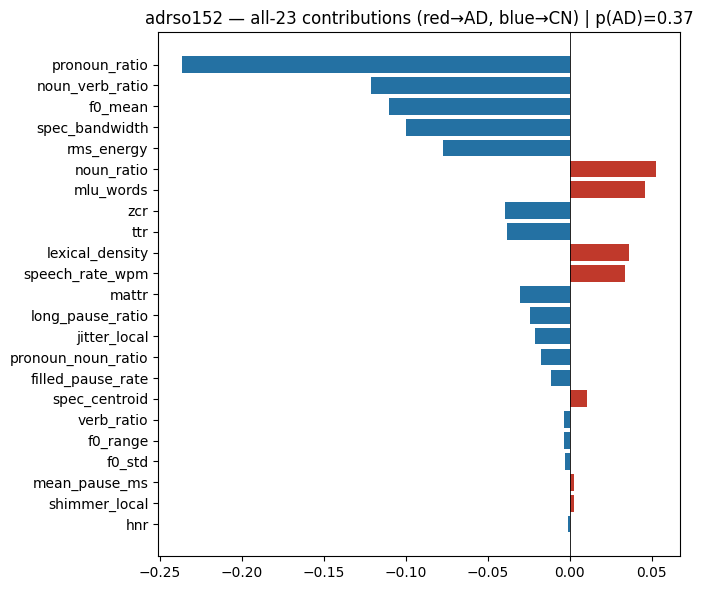


── adrso015  (true: CN) ──
  Predicted control-consistent (62% confidence): reduced pronoun use, reduced average pitch, reduced frequency of long pauses, elevated speech rate.
    pronoun_ratio       -0.209
    f0_mean             -0.167
    long_pause_ratio    -0.150
    speech_rate_wpm     -0.111
    spec_bandwidth      +0.085
    noun_verb_ratio     -0.073
    ttr                 -0.044
    zcr                 +0.043
    mattr               -0.041
    rms_energy          +0.040
    noun_ratio          +0.026
    jitter_local        +0.023
    mlu_words           +0.021
    mean_pause_ms       -0.019
    pronoun_noun_ratio  -0.016
    filled_pause_rate   +0.011
    spec_centroid       -0.011
    f0_std              +0.009
    hnr                 -0.006
    verb_ratio          -0.005
    f0_range            -0.003
    shimmer_local       +0.001
    lexical_density     +0.001


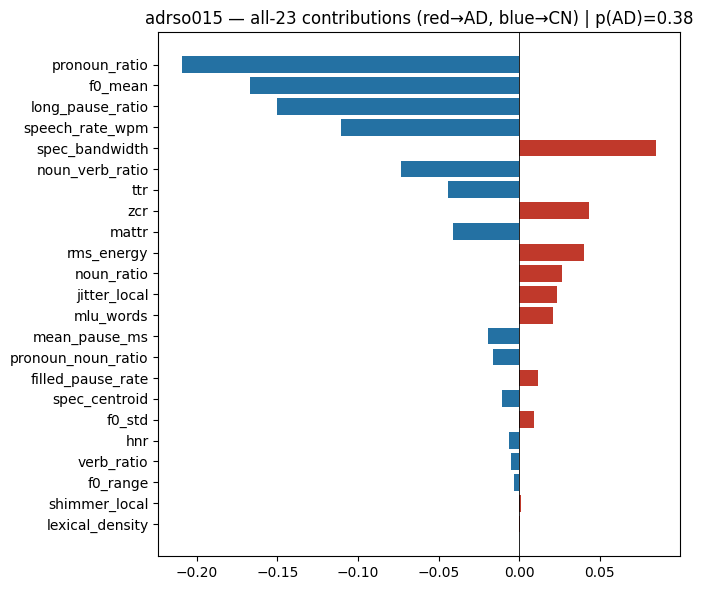


── adrso246  (true: AD) ──
  Predicted Alzheimer's-consistent (54% confidence): elevated speech rate, reduced spectral spread, elevated loudness, reduced frequency of long pauses.
    speech_rate_wpm     -0.208
    spec_bandwidth      +0.205
    rms_energy          +0.176
    long_pause_ratio    -0.172
    f0_std              +0.168
    ttr                 +0.146
    f0_mean             -0.125
    noun_verb_ratio     -0.103
    mattr               -0.102
    filled_pause_rate   +0.085
    pronoun_ratio       -0.082
    zcr                 +0.050
    noun_ratio          +0.044
    mean_pause_ms       -0.042
    spec_centroid       -0.020
    jitter_local        +0.016
    mlu_words           +0.014
    shimmer_local       -0.013
    pronoun_noun_ratio  -0.009
    lexical_density     +0.008
    verb_ratio          -0.008
    f0_range            +0.005
    hnr                 +0.005


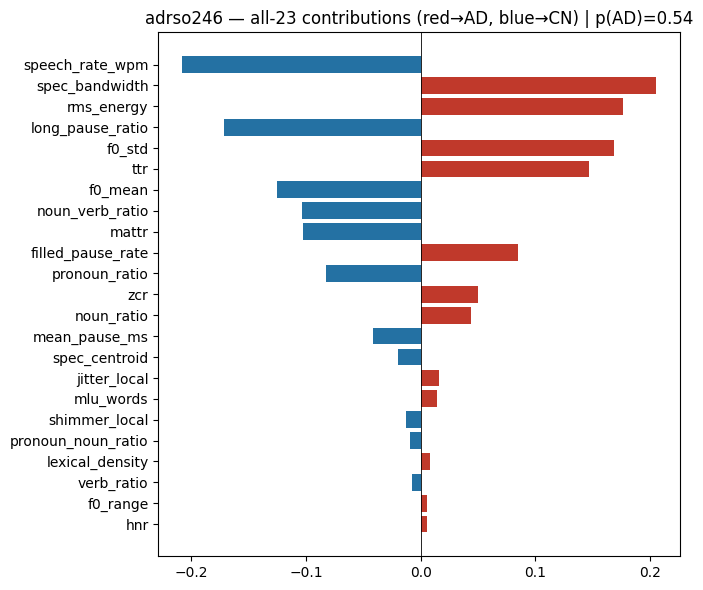

In [ ]:
# Human phrasing for each concept -> readable clinical explanations
PHRASE={"ttr":"vocabulary variety","mattr":"vocabulary variety","mlu_words":"sentence length",
 "pronoun_ratio":"pronoun use","noun_ratio":"noun use","verb_ratio":"verb use",
 "pronoun_noun_ratio":"vague pronoun-vs-noun use","noun_verb_ratio":"noun-vs-verb balance",
 "lexical_density":"content-word density","filled_pause_rate":"filled pauses (um/uh)",
 "speech_rate_wpm":"speech rate","mean_pause_ms":"pause length","long_pause_ratio":"frequency of long pauses",
 "f0_mean":"average pitch","f0_std":"pitch variation","f0_range":"pitch range",
 "jitter_local":"voice jitter","shimmer_local":"voice shimmer","hnr":"voice clarity",
 "spec_centroid":"voice brightness","spec_bandwidth":"spectral spread","zcr":"noisiness","rms_energy":"loudness"}

def explain(i,k=4):
    c=concepts_for(i); contrib=W*c; p=1/(1+np.exp(-(contrib.sum()+b)))
    top=np.argsort(-np.abs(contrib))[:k]
    parts=[f"{'elevated' if c[j]>0 else 'reduced'} {PHRASE.get(CONCEPTS[j],CONCEPTS[j])}" for j in top]
    verdict="Alzheimer's-consistent" if p>=0.5 else "control-consistent"
    return c,contrib,p,f"Predicted {verdict} ({max(p,1-p)*100:.0f}% confidence): "+", ".join(parts)+"."

print("Per-patient natural-language explanation + full 23-concept scorecard:\n")
for i in idx[:3]:
    c,contrib,p,text=explain(i,4)
    print(f"── {FILES[i]}  (true: {'AD' if Y[i] else 'CN'}) ──")
    print("  "+text)
    o=np.argsort(-np.abs(contrib))
    for j in o: print(f"    {CONCEPTS[j]:<20}{contrib[j]:+.3f}")
    plt.figure(figsize=(7,6))
    cc=["#c0392b" if contrib[j]>0 else "#2471a3" for j in o]
    plt.barh([CONCEPTS[j] for j in o][::-1],[contrib[j] for j in o][::-1],color=cc[::-1])
    plt.axvline(0,c="k",lw=.6); plt.title(f"{FILES[i]} — all-23 contributions (red→AD, blue→CN) | p(AD)={p:.2f}")
    plt.tight_layout(); plt.show(); print()

## 10 · Adaptive early-exit — real model truncated at each cutoff (accuracy vs seconds)

Real-model early-exit — held-out test AUC vs seconds of patient speech (mean over 10 seeds):
    10s: AUC 0.732
    20s: AUC 0.822
    30s: AUC 0.818
    45s: AUC 0.798
    60s: AUC 0.788
    90s: AUC 0.793
   full: AUC 0.796

⏱️  Knee ≈ 20s — earliest cutoff within 0.02 AUC of the full recording.


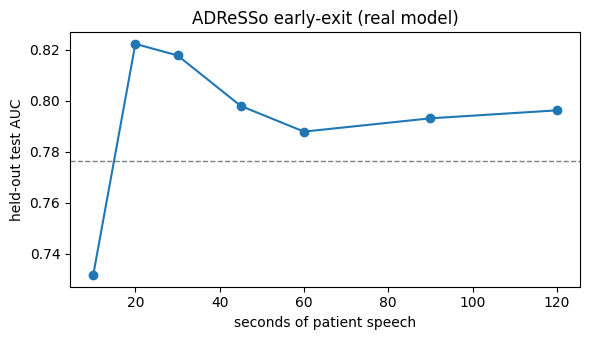

In [ ]:
# Real early-exit: truncate each TEST recording's utterance sequence at a cutoff and
# re-infer with the trained bottleneck model (it masks to `lens`, so it natively handles
# variable-length input). No crude proxy — this is the actual pipeline stopping early.
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

def utt_cutoff_len(fid, cutoff):
    meta = SEG.get(fid, [])
    if cutoff >= 999: return max(1, min(len(meta), MAXU))
    k = sum(1 for rs,_ in meta if rs <= cutoff)
    return max(1, min(k, MAXU))

@torch.no_grad()
def predict_trunc(net, idx, cutoff):
    net.eval(); P=[]; T=[]
    for i in idx:
        L,A,nfull = pad_pair(FILES[i])
        n = min(utt_cutoff_len(FILES[i], cutoff), nfull)
        logit,_ = net(torch.from_numpy(L)[None].to(DEVICE),
                      torch.from_numpy(A)[None].to(DEVICE),
                      torch.tensor([n]).to(DEVICE))
        P.append(torch.sigmoid(logit).item()); T.append(Y[i])
    return np.array(P), np.array(T)

curves = {c: [] for c in CFG.CUTOFFS_S}
for s in CFG.SEEDS:
    tr,va,te = split_idx(s)
    sc = StandardScaler().fit(C_all[tr]); C = sc.transform(C_all).astype("float32")
    net,_,_,_,_,_ = train_once(tr,va,te,C,True,s)          # same trained model as the results section (seeded)
    for c in CFG.CUTOFFS_S:
        Pt,Tt = predict_trunc(net, te, c)
        if len(set(Tt))>1: curves[c].append(roc_auc_score(Tt,Pt))
curve = {c: float(np.mean(v)) for c,v in curves.items() if v}
full = curve[999]

print("Real-model early-exit — held-out test AUC vs seconds of patient speech (mean over %d seeds):" % len(CFG.SEEDS))
for c in CFG.CUTOFFS_S:
    if c in curve: print(f"  {('full' if c>=999 else str(c)+'s'):>5}: AUC {curve[c]:.3f}")
knee = next((c for c in CFG.CUTOFFS_S if c in curve and curve[c] >= full - CFG.KNEE_TOL), 999)
print(f"\n⏱️  Knee ≈ {knee}s — earliest cutoff within {CFG.KNEE_TOL} AUC of the full recording.")
try:
    import matplotlib.pyplot as plt
    cs=[c for c in CFG.CUTOFFS_S if c in curve]
    xs=[c if c<999 else max([x for x in cs if x<999]+[60])+30 for c in cs]
    plt.figure(figsize=(6,3.5)); plt.plot(xs,[curve[c] for c in cs],"o-")
    plt.axhline(full-CFG.KNEE_TOL,ls="--",c="gray",lw=1)
    plt.xlabel("seconds of patient speech"); plt.ylabel("held-out test AUC")
    plt.title("ADReSSo early-exit (real model)"); plt.tight_layout(); plt.show()
except Exception as e: print("(plot skipped)", e)

## 9 · Explainability audit — all 23 concepts
Global importance (all 23) + **concept fidelity** (do the bottleneck neurons recover the real markers?) + **group-difference** validation (do markers move the clinically-expected way?) + per-patient natural-language explanations and full scorecards.